# 13. XGBoost Classifier

**Project** · Employee Attrition Prediction  
**Problem type** · Classification

This dataset is synthetic and designed for education. Keep its predictions within the exercise. Any real-world financial, medical, safety, educational or employment decision requires independent evidence and validation.

Start with Sections 1–9 for your first model. Then try parameter tuning and the interview exercises. Run the code cells in order because each step uses results from earlier cells.

## 1. Introduction

XGBoost builds an additive model one tree at a time. For binary classification, each tree updates the current log-odds score to reduce classification loss. The algorithm can learn that overtime matters more under some work-life balance levels.

By the end, you can implement the pipeline, explain how it predicts and use holdout results to identify where it struggles.

## 2. Understand the Dataset

Lower satisfaction, income, tenure, promotion counts and work-life balance increase a log-odds score. Overtime increases it, especially when work-life balance is low. Tenure of at least five years without a promotion adds another term. The label is sampled from the sigmoid probability.

| Column | Type | Units or values | Meaning |
| --- | --- | --- | --- |
| `job_satisfaction` | integer | ordinal 1 to 5 | Self-reported satisfaction level |
| `monthly_income_usd` | integer | USD/month | Gross monthly income |
| `years_at_company` | integer | years | Tenure at the company |
| `overtime` | string | Yes or No | Whether overtime is worked |
| `past_promotions` | integer | count | Promotions already earned |
| `work_life_balance` | integer | ordinal 1 to 5 | Reported work-life balance |
| `attrition` | string | Staying, Leaving | Observed class label |

**Independent variables (X)** · `job_satisfaction`, `monthly_income_usd`, `years_at_company`, `overtime`, `past_promotions`, `work_life_balance`.

**Dependent variable (y)** · `attrition` is the class to predict. The preview shows the first 10 rows, dimensions and stored types. Blank features, where present, are intentional.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display

csv_name = "13_employee_attrition.csv"
csv_path = Path("../datasets") / csv_name

# Also look in the project folder or the location used for Colab uploads.
if not csv_path.is_file():
    csv_path = Path("datasets") / csv_name
if not csv_path.is_file():
    csv_path = Path("Machine_Learning_Complete_Guide/datasets") / csv_name
if not csv_path.is_file():
    csv_path = Path(csv_name)

df = pd.read_csv(csv_path, keep_default_na=False, na_values=[""])
print("Dataset shape:", df.shape)
display(df.head(10))
display(df.dtypes)

Dataset shape: (1500, 7)


,job_satisfaction,monthly_income_usd,years_at_company,overtime,past_promotions,work_life_balance,attrition
0,4,5985,12,No,2,3.0,Staying
1,2,3296,19,No,1,NaN,Leaving
2,2,7285,8,No,0,1.0,Staying
3,4,6834,12,Yes,2,1.0,Staying
4,5,7921,21,Yes,2,4.0,Staying
5,3,8093,1,Yes,0,1.0,Leaving
6,3,8178,0,Yes,0,1.0,Leaving
7,5,10349,11,No,1,2.0,Staying
8,1,7592,4,Yes,1,2.0,Leaving
9,1,3080,20,No,5,3.0,Staying


job_satisfaction        int64
monthly_income_usd      int64
years_at_company        int64
overtime                  str
past_promotions         int64
work_life_balance     float64
attrition                 str
dtype: object

## 3. Mathematical Understanding

At round $t$, update the model score using $F_t(x)=F_{t-1}(x)+\eta f_t(x)$, where $x$ is a row, $F$ is a log-odds score, $f_t$ is the new tree’s leaf score and $\eta$ is the learning rate. The probability is $p=\sigma(F)=1/(1+e^{-F})$. For binary log loss with label $y$, the gradient is $g=p-y$ and the second derivative is $h=p(1-p)$. For a leaf with sums $G=\sum g$ and $H=\sum h$, the L2-regularized leaf update before shrinkage is $w=-G/(H+\lambda)$, where $\lambda$ is the L2 leaf-weight penalty. XGBoost uses both gradients and curvature to score candidate updates.

If a leaf groups labels $1,1,0$ and each row starts at $p=0.5$, then $G=-0.5$, $H=0.75$. With $\lambda=1$, its leaf score is $0.286$. A learning rate of $0.1$ raises the log-odds from $0$ to about $0.0286$ and the probability to about $0.507$.

[XGBoost model tutorial](https://xgboost.readthedocs.io/en/stable/tutorials/model.html)

## 4. Working Principle

Start with an initial score, compute gradients and second derivatives of the current binary loss, build a tree using a regularized score and add a scaled leaf update. Repeat so later trees respond to remaining errors. Apply the sigmoid and select a class at prediction time.

| Step | Value |
| --- | --- |
| Initial score | 0 |
| Unshrunk update | 0.286 |
| Shrunken update | 0.0286 |
| Updated probability | 0.507 |

**Workflow diagram**

`Raw input` → `Imputed numeric values and any category indicators` → `Adds regularized trees to improve binary log loss` → `Class prediction`.

## 5. Dataset Exploration

The first and last rows verify parsing. Shape and info reveal size, stored types and non-missing counts. Summary statistics show typical values, ranges and spread. Missingness and duplicate counts identify possible cleanup needs. The target plot shows class balance. Feature plots show variation. Pearson correlation measures linear association. The category target is excluded. The features and evaluation design are fixed before modeling.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
TARGET = "attrition"
FEATURES = ["job_satisfaction","monthly_income_usd","years_at_company","overtime","past_promotions","work_life_balance"]
NUMERIC = ["job_satisfaction","monthly_income_usd","years_at_company","past_promotions","work_life_balance"]
CATEGORICAL = ["overtime"]
SEED = 42
LABELS = ["Staying","Leaving"]

In [3]:
df.info()
display(df.head())
display(df.tail())
display(df.describe(include="all").T)
display(pd.DataFrame({"Missing": df.isna().sum(), "Missing %": 100 * df.isna().mean()}).round(1))
print("Exact duplicate rows:", df.duplicated().sum())
print("Repeated feature rows:", df.duplicated(subset=FEATURES).sum())

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   job_satisfaction    1500 non-null   int64  
 1   monthly_income_usd  1500 non-null   int64  
 2   years_at_company    1500 non-null   int64  
 3   overtime            1470 non-null   str    
 4   past_promotions     1500 non-null   int64  
 5   work_life_balance   1470 non-null   float64
 6   attrition           1500 non-null   str    
dtypes: float64(1), int64(4), str(2)
memory usage: 95.9 KB


,job_satisfaction,monthly_income_usd,years_at_company,overtime,past_promotions,work_life_balance,attrition
0,4,5985,12,No,2,3.0,Staying
1,2,3296,19,No,1,NaN,Leaving
2,2,7285,8,No,0,1.0,Staying
3,4,6834,12,Yes,2,1.0,Staying
4,5,7921,21,Yes,2,4.0,Staying


,job_satisfaction,monthly_income_usd,years_at_company,overtime,past_promotions,work_life_balance,attrition
1495,5,10133,8,No,2,1.0,Staying
1496,2,6135,19,No,1,1.0,Staying
1497,1,4260,9,No,0,3.0,Staying
1498,4,10049,5,No,0,3.0,Staying
1499,5,5876,15,No,0,4.0,Staying


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
job_satisfaction,1500.0,NaN,NaN,NaN,2.972,1.39637,1.0,2.0,3.0,4.0,5.0
monthly_income_usd,1500.0,NaN,NaN,NaN,7357.482667,2931.325938,2302.0,4814.5,7412.5,9877.25,12494.0
years_at_company,1500.0,NaN,NaN,NaN,11.084667,6.484561,0.0,5.0,11.0,17.0,22.0
overtime,1470,2,No,1003,NaN,NaN,NaN,NaN,NaN,NaN,NaN
past_promotions,1500.0,NaN,NaN,NaN,1.364667,1.35631,0.0,0.0,1.0,2.0,5.0
work_life_balance,1470.0,NaN,NaN,NaN,3.003401,1.403337,1.0,2.0,3.0,4.0,5.0
attrition,1500,2,Staying,1149,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Missing,Missing %
job_satisfaction,0,0.0
monthly_income_usd,0,0.0
years_at_company,0,0.0
overtime,30,2.0
past_promotions,0,0.0
work_life_balance,30,2.0
attrition,0,0.0


Exact duplicate rows: 0
Repeated feature rows: 0


### Plot the target

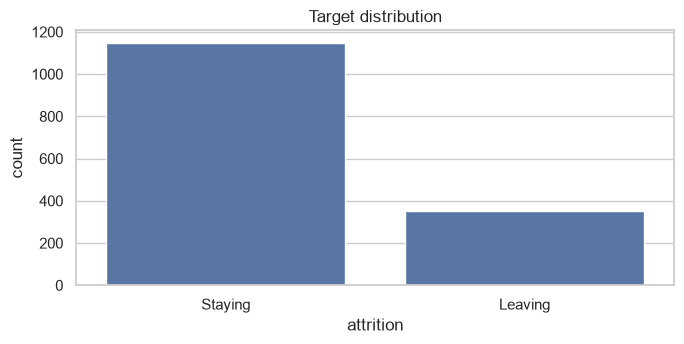

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.6))
sns.countplot(data=df, x=TARGET, order=LABELS, ax=ax)
ax.set_title("Target distribution")
fig.tight_layout()
plt.show()

### Look at the input features

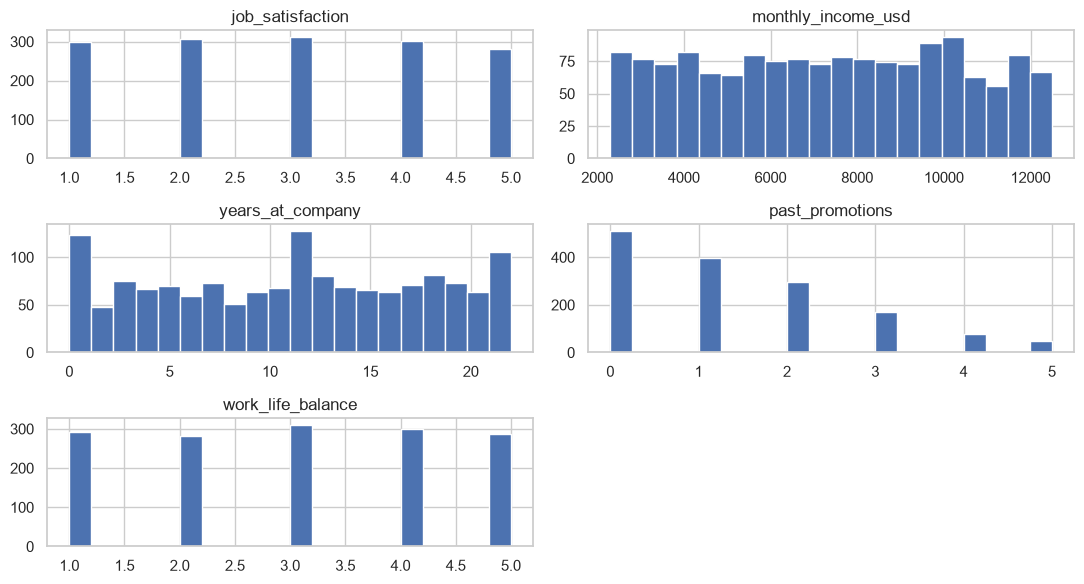

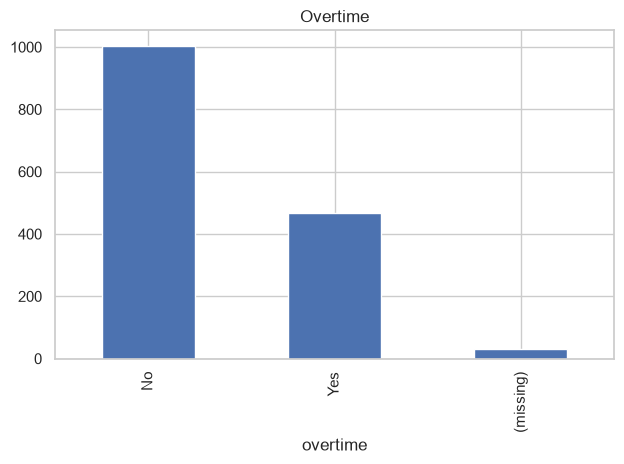

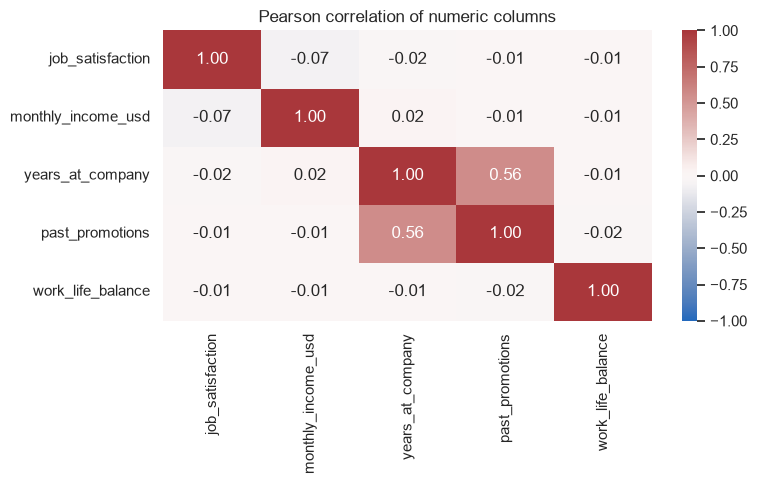

In [5]:
df[NUMERIC].hist(figsize=(11, 6), bins=20)
plt.tight_layout()
plt.show()

df["overtime"].fillna("(missing)").value_counts().plot.bar()
plt.title("Overtime")
plt.tight_layout()
plt.show()

correlation_columns = NUMERIC
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(df[correlation_columns].corr(), annot=True, fmt=".2f", cmap="vlag",
            center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Pearson correlation of numeric columns")
fig.tight_layout()
plt.show()

## 6. Data Preprocessing

Select the input columns and target explicitly. Stratification preserves approximate class proportions. The numeric branch fills blanks using training medians. The categorical branch fills blanks with the most common training level and one-hot encodes levels. An unseen level becomes an all-zero block. Tree splits use the ordering of values, so scaling is unnecessary. The pipeline fits each preprocessing step after the split and repeats it in each training fold.

Exact and feature-only duplicate counts are listed above. Identical measurements with distinct outcomes can represent legitimate observations.

### 1. Choose the inputs and target

In [6]:
# X contains the inputs. y contains the answer for each row.
X = df[FEATURES]
label_codes = {'Staying': 0, 'Leaving': 1}
y = df[TARGET].map(label_codes)

### 2. Split the rows into training and test sets

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 1200
Test rows: 300


### 3. Prepare the columns

The next cell sets up the cleaning steps. They learn their values later, when you fit the model.

In [8]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Fill blank numbers with the training median.
numeric_preprocess = SimpleImputer(strategy="median")

# Fill blank categories, then make one indicator column per category.
category_preprocess = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocess = ColumnTransformer(
    [
        ("numeric", numeric_preprocess, NUMERIC),
        ("categorical", category_preprocess, CATEGORICAL),
    ],
    verbose_feature_names_out=False,
)

## 7. Model Implementation

`n_estimators` chooses boosting rounds, `learning_rate` shrinks each update, `max_depth` limits interaction complexity and `reg_lambda` penalizes extreme leaf weights. `tree_method='hist'` uses binned split candidates. Labels are encoded as 0 = Staying and 1 = Leaving.

- The estimator import provides the algorithm implementation.
- `Pipeline` joins preprocessing and the model in execution order.
- `fit(X_train, y_train)` learns transformations and parameters from training rows.
- `predict(...)` applies the fitted steps to new rows. The first holdout row gives a preview before scoring the entire split.

### Create the model

In [9]:
from xgboost import XGBClassifier

estimator = XGBClassifier(objective="binary:logistic", eval_metric="logloss", n_estimators=100, max_depth=3, learning_rate=0.08, reg_lambda=2.0, tree_method="hist", random_state=SEED, n_jobs=2)
model = Pipeline([
    ("preprocess", preprocess),
    ("model", estimator),
])

### Fit on the training rows

In [10]:
# Learn from the training rows.
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['job_satisfaction','monthly_income_usd','years_at_company','overtime', 'past_promotions','work_life_balance']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generat

### Predict on the test rows

In [11]:
# Predict using the held-out inputs.
predictions = model.predict(X_test)
display(X_test.head(1))
print("Example predicted class:", LABELS[predictions[0]])

,job_satisfaction,monthly_income_usd,years_at_company,overtime,past_promotions,work_life_balance
467,3,10632,16,Yes,0,2.0


Example predicted class: Leaving


## 8. Model Evaluation

Let $TP$ count correctly predicted positives, $TN$ correctly predicted negatives, $FP$ false positives, $FN$ false negatives and $N$ all test rows. Higher values indicate better scores, subject to the baseline and the costs of different errors.

| Measure | Formula and interpretation |
| --- | --- |
| Accuracy | $(TP+TN)/N$ for binary outcomes, or the proportion of correct predictions for multiple classes. |
| Precision | $TP/(TP+FP)$. Of the predicted positives, how many really were positive? |
| Recall | $TP/(TP+FN)$. Of the actual positives, how many did the model catch? |
| F1 | $2PR/(P+R)$ for precision $P$ and recall $R$. It is their harmonic mean. |
| ROC-AUC | Area $\int_0^1 \mathrm{TPR}\,d(\mathrm{FPR})$, with $\mathrm{TPR}=TP/(TP+FN)$ and $\mathrm{FPR}=FP/(FP+TN)$. Binary AUC measures the chance of ranking a random positive above a random negative, counting ties as half. Around 0.5 corresponds to chance ranking. |
| Confusion matrix | Entry $(i,j)$ counts rows with actual class $i$ and predicted class $j$. A strong diagonal indicates correct classifications. Examine the off-diagonal cells for costly errors. |
| Classification report | Applies precision, recall and F1 per class. Support counts actual examples per class. Macro averaging weights classes equally, and weighted averaging uses support. |

The positive class is **Leaving**. ROC-AUC ranks by its estimated probability. A prior-only classifier gives a baseline. A class with no positive predictions gets zero precision by convention.

In [12]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, ConfusionMatrixDisplay, RocCurveDisplay)

AVERAGE = "binary"
CLASS_IDS = np.arange(len(LABELS))

test_scores = model.predict_proba(X_test)[:, 1]

initial_metrics = {
    "Accuracy": accuracy_score(y_test, predictions),
    "Precision": precision_score(y_test, predictions, average=AVERAGE, zero_division=0),
    "Recall": recall_score(y_test, predictions, average=AVERAGE, zero_division=0),
    "F1": f1_score(y_test, predictions, average=AVERAGE, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_scores),
}
display(pd.Series(initial_metrics, name="Test score").round(3))

Accuracy     0.830
Precision    0.788
Recall       0.371
F1           0.505
ROC-AUC      0.824
Name: Test score, dtype: float64

### Compare with a simple baseline

In [13]:
# A baseline knows the training class frequencies and sees no input features.
baseline = DummyClassifier(strategy="prior")
baseline_train = np.zeros((len(y_train), 1))
baseline_test = np.zeros((len(y_test), 1))
baseline.fit(baseline_train, y_train)

baseline_predictions = baseline.predict(baseline_test)
baseline_scores = baseline.predict_proba(baseline_test)[:, 1]

baseline_metrics = {
    "Accuracy": accuracy_score(y_test, baseline_predictions),
    "Precision": precision_score(y_test, baseline_predictions, average=AVERAGE, zero_division=0),
    "Recall": recall_score(y_test, baseline_predictions, average=AVERAGE, zero_division=0),
    "F1": f1_score(y_test, baseline_predictions, average=AVERAGE, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, baseline_scores),
}
display(pd.DataFrame([baseline_metrics, initial_metrics], index=["Baseline", "Model"]).round(3))

,Accuracy,Precision,Recall,F1,ROC-AUC
Baseline,0.767,0.000,0.000,0.000,0.500
Model,0.830,0.788,0.371,0.505,0.824


### Read the results for each class

In [14]:
print(classification_report(
    y_test, predictions, labels=CLASS_IDS, target_names=LABELS, zero_division=0
))

              precision    recall  f1-score   support

     Staying       0.84      0.97      0.90       230
     Leaving       0.79      0.37      0.50        70

    accuracy                           0.83       300
   macro avg       0.81      0.67      0.70       300
weighted avg       0.82      0.83      0.81       300



## 9. Visualizations

Read the confusion matrix by row for each actual class. Off-diagonal cells show the direction and size of confusions. The ROC curve shows the recall and false-positive trade-off across score thresholds.

Gain importance summarizes average objective improvement from splits on each encoded feature, normalized for display. Inspect it to see how the fitted trees use the inputs.

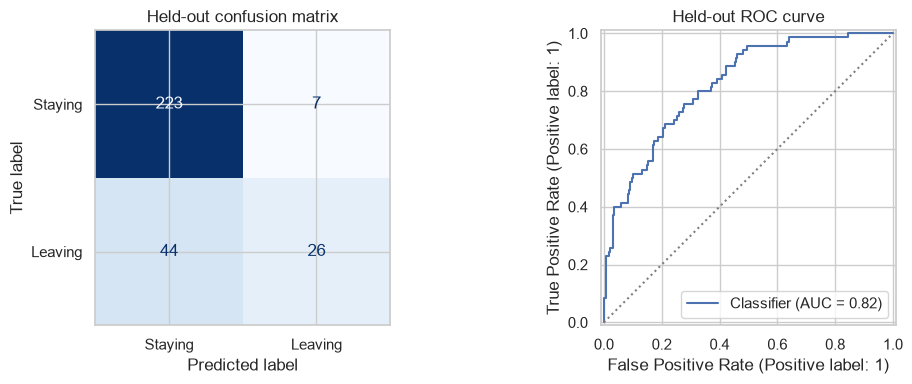

In [15]:
fig, (ax, roc_ax) = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, predictions, labels=CLASS_IDS, display_labels=LABELS,
                                        colorbar=False, cmap="Blues", ax=ax)
ax.set_title("Held-out confusion matrix")
RocCurveDisplay.from_predictions(y_test, test_scores, pos_label=1, ax=roc_ax)
roc_ax.plot([0, 1], [0, 1], linestyle=":", color="grey")
roc_ax.set_title("Held-out ROC curve")
fig.tight_layout()
plt.show()

### A closer look at this model

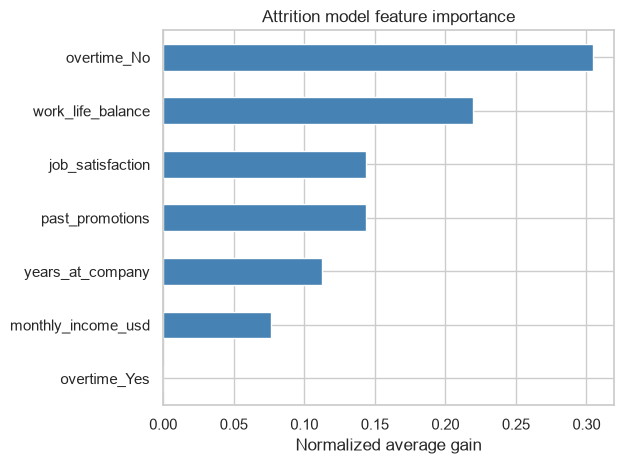

In [16]:
booster = model.named_steps["model"]
gain = pd.Series(booster.feature_importances_, index=model.named_steps["preprocess"].get_feature_names_out())
ax = gain.sort_values().plot.barh(color="steelblue")
ax.set(xlabel="Normalized average gain", title="Attrition model feature importance")
plt.tight_layout()
plt.show()

## 10. Hyperparameter Tuning

GridSearchCV tries the grid with three shuffled stratified folds within the training data. Each candidate gets a freshly fitted pipeline per fold. Rank by positive-class F1. `refit=True` fits the winner on all training rows. Use the CV ranks to choose parameters and the holdout to report performance.

`n_estimators` chooses boosting rounds, `learning_rate` shrinks each update, `max_depth` limits interaction complexity and `reg_lambda` penalizes extreme leaf weights. `tree_method='hist'` uses binned split candidates. Labels are encoded as 0 = Staying and 1 = Leaving.

[GridSearchCV documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)

### Set up the candidate settings

In [17]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = {"model__n_estimators": [60, 120], "model__learning_rate": [0.05, 0.15],
 "model__max_depth": [2, 4], "model__reg_lambda": [1, 5]}
validation = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
search = GridSearchCV(model, param_grid, scoring="f1", cv=validation,
                      refit=True, n_jobs=1, error_score="raise")

### Search using training rows

In [18]:
search.fit(X_train, y_train)
tuned_model = search.best_estimator_
results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
results["Mean CV F1"] = results["mean_test_score"]
print("Best training-CV parameters:", search.best_params_)
display(results[["rank_test_score", "Mean CV F1", "std_test_score", "params"]].head().round(3))

Best training-CV parameters: {'model__learning_rate': 0.15, 'model__max_depth': 4, 'model__n_estimators': 60, 'model__reg_lambda': 1}


,rank_test_score,Mean CV F1,std_test_score,params
12,1,0.477,0.027,"{'model__learning_rate': 0.15, 'model__max_dep..."
11,2,0.469,0.033,"{'model__learning_rate': 0.15, 'model__max_dep..."
14,3,0.468,0.041,"{'model__learning_rate': 0.15, 'model__max_dep..."
10,4,0.461,0.019,"{'model__learning_rate': 0.15, 'model__max_dep..."
13,5,0.458,0.025,"{'model__learning_rate': 0.15, 'model__max_dep..."


### Compare the models on the test set

In [19]:
tuned_predictions = tuned_model.predict(X_test)
tuned_scores = tuned_model.predict_proba(X_test)[:, 1]

tuned_metrics = {
    "Accuracy": accuracy_score(y_test, tuned_predictions),
    "Precision": precision_score(y_test, tuned_predictions, average=AVERAGE, zero_division=0),
    "Recall": recall_score(y_test, tuned_predictions, average=AVERAGE, zero_division=0),
    "F1": f1_score(y_test, tuned_predictions, average=AVERAGE, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, tuned_scores),
}
comparison = pd.DataFrame(
    [baseline_metrics, initial_metrics, tuned_metrics],
    index=["Baseline", "First model", "Tuned model"],
)
display(comparison.round(3))

,Accuracy,Precision,Recall,F1,ROC-AUC
Baseline,0.767,0.000,0.000,0.000,0.500
First model,0.830,0.788,0.371,0.505,0.824
Tuned model,0.813,0.706,0.343,0.462,0.806


## 11. Real-World Prediction

Pass three new examples to the CV-selected pipeline. The result shows the estimated probability of each class. Read those estimates in the context of the synthetic population.

### Enter three new examples

In [20]:
examples = pd.DataFrame([
    [2, 4300, 7, 'Yes', 0, 2],
    [5, 10100, 12, 'No', 3, 5],
    [3, 6100, 4, 'Yes', 1, 3],
], columns=FEATURES)
display(examples)

,job_satisfaction,monthly_income_usd,years_at_company,overtime,past_promotions,work_life_balance
0,2,4300,7,Yes,0,2
1,5,10100,12,No,3,5
2,3,6100,4,Yes,1,3


### Make predictions

In [21]:
sample_inputs = examples
prediction_model = tuned_model
sample_predictions = prediction_model.predict(sample_inputs)
example_output = examples.copy()
example_output["Scenario"] = ["Frequent overtime and low satisfaction profile","Longer tenure with promotions and high satisfaction","Intermediate profile with overtime"]
probabilities = prediction_model.predict_proba(sample_inputs)
example_output["Predicted class"] = np.take(LABELS, sample_predictions)

# Each row contains the class probabilities for one new example.
probability_table = pd.DataFrame(probabilities.round(3), columns=LABELS)
probability_table = probability_table.add_prefix("P(").add_suffix(")")
example_output = pd.concat([example_output, probability_table], axis=1)
display(example_output)

,job_satisfaction,monthly_income_usd,years_at_company,overtime,past_promotions,work_life_balance,Scenario,Predicted class,P(Staying),P(Leaving)
0,2,4300,7,Yes,0,2,Frequent overtime and low satisfaction profile,Leaving,0.279,0.721
1,5,10100,12,No,3,5,Longer tenure with promotions and high satisfa...,Staying,0.995,0.005
2,3,6100,4,Yes,1,3,Intermediate profile with overtime,Staying,0.822,0.178


## 12. Limitations and Advantages

Boosting is flexible and often learns tabular interactions well. It takes tuning and does not make an importance chart causal. Very shallow or few trees can underfit. Large depths and aggressive updates can overfit noise. Use for predictive tabular benchmarking when local explanations and validation are possible. Compare simpler models when transparent decisions are required.

## 13. Interview Preparation

### A. 30-second explanation

> I predicted synthetic employee attrition with gradient-boosted classification trees. The model updates log-odds sequentially using the loss gradients and curvature. I tuned depth, learning rate, rounds and regularization on training folds and inspected how well it identified the Leaving class.

### B. 90-second technical explanation

> I predicted synthetic employee attrition with gradient-boosted classification trees. The model updates log-odds sequentially using the loss gradients and curvature. I tuned depth, learning rate, rounds and regularization on training folds and inspected how well it identified the Leaving class. My target was attrition, and the inputs were job satisfaction, monthly income usd, years at company, overtime, past promotions, work life balance. Start with an initial score, compute gradients and second derivatives of the current binary loss, build a tree using a regularized score and add a scaled leaf update. Repeat so later trees respond to remaining errors. Apply the sigmoid and select a class at prediction time. I held out 20% of the rows and fitted preprocessing within each training fold. I compared F1 and ROC-AUC with a prior baseline and read the confusion matrix to identify the classes that were easiest to confuse. The inputs and labels were generated for teaching, so the holdout performance describes this exercise. For real data I would confirm which inputs are available at prediction time and build a split that reflects where the model will be used.

### C. Ten technical questions

1. **What does a new tree predict?** A contribution to the raw model score, measured in log-odds for the binary logistic objective.
2. **What does p minus y represent?** The derivative of binary log loss with respect to the raw score.
3. **How does boosting differ from random forests?** Boosting updates sequentially using current errors. Random forests fit randomized trees independently and average outputs.
4. **What is shrinkage?** Multiplying each tree update by the learning rate.
5. **What does reg_lambda control?** L2 regularization of leaf scores.
6. **Why tune learning rate and rounds together?** Smaller updates often need more rounds to reach a comparable fit.
7. **What does hist change?** It uses histograms of feature bins to evaluate split candidates efficiently.
8. **Why do positive labels need a documented mapping?** The encoded positive class determines the probability column and binary metrics.
9. **What is gain importance?** A split-based summary of the loss improvements credited to a feature, averaged with XGBoost’s gain setting.
10. **Why might training loss keep falling after validation loss worsens?** Later rounds can fit training noise.

### D. Five scenario questions

1. **The validation score plateaus while training error improves. What would you try?** Reduce depth or rounds, increase regularization, or use early stopping with a separate validation set.
2. **Leaving is much rarer in a new cohort. What should you check?** Review calibration and threshold trade-offs on representative recent cohorts.
3. **The inputs include termination date. Can it go into training?** Exclude it because it becomes known after the event being predicted.
4. **Overtime ranks highest by gain. What does it establish?** The trained trees use this feature to make predictive splits. It does not establish causation.
5. **You need a reason for individual predictions. What could you inspect?** Compare local feature attributions and test their stability, with appropriate contextual review.

### E. Three common mistakes

- Averaging class labels from boosting trees. Add score contributions before applying the sigmoid.
- Calling gradients raw class residuals without sign or scale. Distinguish p − y from its negative.
- Picking the final round using the test set. Use validation.

### F. Complete project explanation

Use the measured scores in a short project walkthrough. Start with the problem, explain the pipeline and close with what the evaluation can support. This cell inserts results from the current run.

In [22]:
from IPython.display import Markdown

summary = (
    "I built a supervised classification project for employee attrition prediction using XGBoost Classifier. I generated 1,500 synthetic observations and used job satisfaction, monthly income usd, years at company, overtime, past promotions, work life balance to predict attrition. I used a holdout and a preprocessing pipeline fitted within training folds. I compared the selected estimator with a simple baseline. "
    f"On the holdout, the CV-selected model reached {tuned_metrics['F1']:.3f} F1 for Leaving, versus "
    f"{baseline_metrics['F1']:.3f} for the baseline, with ROC-AUC {tuned_metrics['ROC-AUC']:.3f}. "
    "I used gain importance to see which encoded features were useful for splitting attrition profiles. These results apply to the synthetic data and should be validated on representative observations before practical use."
)
display(Markdown("> " + summary))

> I built a supervised classification project for employee attrition prediction using XGBoost Classifier. I generated 1,500 synthetic observations and used job satisfaction, monthly income usd, years at company, overtime, past promotions, work life balance to predict attrition. I used a holdout and a preprocessing pipeline fitted within training folds. I compared the selected estimator with a simple baseline. On the holdout, the CV-selected model reached 0.462 F1 for Leaving, versus 0.000 for the baseline, with ROC-AUC 0.806. I used gain importance to see which encoded features were useful for splitting attrition profiles. These results apply to the synthetic data and should be validated on representative observations before practical use.